# Experiment 8: Clustering Human Activity Recognition Data using K-Means, DBSCAN, and Hierarchical Clustering
---

## Executive Abstract
This laboratory experiment investigates unsupervised machine learning clustering paradigms applied to high-dimensional sensor measurements from the benchmark **Human Activity Recognition (HAR) Using Smartphones Dataset**. Three foundational clustering architectures are implemented, optimized, and evaluated:
1. **Model A: K-Means Clustering** – Partition-based centroid optimization evaluated across cluster counts $k \in [2, 8]$ using the Within-Cluster Sum of Squares (WCSS/Inertia) Elbow Method and Silhouette Analysis.
2. **Model B: DBSCAN (Density-Based Spatial Clustering of Applications with Noise)** – Non-parametric density connectivity clustering optimized via $k$-nearest neighbor distance knees in principal component projection space.
3. **Model C: Hierarchical Agglomerative Clustering (HAC)** – Bottom-up tree hierarchy generation evaluating Ward's minimum variance criterion alongside Single, Complete, and Average linkages with dendrogram analysis.

Model evaluation integrates both **Internal Validation Metrics** (Silhouette Coefficient, Davies–Bouldin Index, Calinski–Harabasz Index) and **External Ground-Truth Alignment Metrics** (Adjusted Rand Index, Normalized Mutual Information, and cluster contingency matrices).


## 1. Theoretical Foundation and Mathematical Formulation

### 1.1 K-Means Clustering
Given a standardized continuous dataset $\mathbf{X} = \{\mathbf{x}_1, \mathbf{x}_2, \dots, \mathbf{x}_N\} \subset \mathbb{R}^D$, K-Means partitions the $N$ observations into $k$ disjoint Voronoi regions $\mathcal{S} = \{S_1, S_2, \dots, S_k\}$ by minimizing the Within-Cluster Sum of Squares (WCSS / Inertia):
$$\mathcal{J}_{\text{WCSS}}(\mathcal{S}) = \sum_{j=1}^{k} \sum_{\mathbf{x}_i \in S_j} \|\mathbf{x}_i - \boldsymbol{\mu}_j\|^2$$
where $\boldsymbol{\mu}_j$ is the centroid of partition $S_j$:
$$\boldsymbol{\mu}_j = \frac{1}{|S_j|} \sum_{\mathbf{x}_i \in S_j} \mathbf{x}_i$$
Optimization proceeds iteratively via Lloyd's algorithm until cluster assignment stabilized convergence.

### 1.2 DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
DBSCAN defines clusters as continuous regions of high point density separated by contiguous regions of low point density. Given parameters $\epsilon > 0$ (neighborhood radius) and $\text{minPts} \in \mathbb{N}$ (minimum cardinality threshold):
1. **$\epsilon$-Neighborhood:** $N_\epsilon(\mathbf{p}) = \{\mathbf{q} \in \mathbf{X} \mid \text{dist}(\mathbf{p}, \mathbf{q}) \le \epsilon\}$.
2. **Core Point:** A point $\mathbf{p}$ is a core point if $|N_\epsilon(\mathbf{p})| \ge \text{minPts}$.
3. **Directly Density-Reachable:** $\mathbf{q}$ is directly density-reachable from $\mathbf{p}$ if $\mathbf{p}$ is a core point and $\mathbf{q} \in N_\epsilon(\mathbf{p})$.
4. **Density-Connected:** $\mathbf{p}$ and $\mathbf{q}$ are density-connected if there exists an anchor $\mathbf{o}$ such that both $\mathbf{p}$ and $\mathbf{q}$ are density-reachable from $\mathbf{o}$.
5. **Noise:** Any point not belonging to any density-connected component is classified as noise (assigned cluster label $-1$).

### 1.3 Hierarchical Agglomerative Clustering (HAC)
HAC begins with $N$ singleton clusters and iteratively merges the pair of clusters $(A, B)$ minimizing a linkage metric:
- **Ward's Minimum Variance Linkage:** Merges clusters that minimize the increase in total within-cluster sum of squares:
  $$\Delta \text{ESS}(A, B) = \frac{|A| \cdot |B|}{|A| + |B|} \|\boldsymbol{\mu}_A - \boldsymbol{\mu}_B\|^2$$
- **Average Linkage (UPGMA):** $d_{\text{avg}}(A, B) = \frac{1}{|A||B|} \sum_{\mathbf{x} \in A} \sum_{\mathbf{y} \in B} \|\mathbf{x} - \mathbf{y}\|$
- **Complete Linkage:** $d_{\text{max}}(A, B) = \max_{\mathbf{x} \in A, \mathbf{y} \in B} \|\mathbf{x} - \mathbf{y}\|$
- **Single Linkage:** $d_{\text{min}}(A, B) = \min_{\mathbf{x} \in A, \mathbf{y} \in B} \|\mathbf{x} - \mathbf{y}\|$

Tree fidelity is quantified by the **Cophenetic Correlation Coefficient** $c = \frac{\sum_{i < j} (d_{ij} - \bar{d})(t_{ij} - \bar{t})}{\sqrt{\sum_{i < j}(d_{ij} - \bar{d})^2 \sum_{i < j}(t_{ij} - \bar{t})^2}}$.

### 1.4 Clustering Validation Metrics
- **Silhouette Coefficient ($s_i$):** $s_i = \frac{b(i) - a(i)}{\max(a(i), b(i))}$, where $a(i)$ is mean intra-cluster distance and $b(i)$ is nearest-cluster distance.
- **Davies–Bouldin Index ($DB$):** $DB = \frac{1}{k} \sum_{i=1}^k \max_{j \ne i} \left(\frac{R_i + R_j}{d(c_i, c_j)}\right)$ (lower is superior).
- **Calinski–Harabasz Index ($CH$):** $CH = \frac{\text{Tr}(B_k)/(k-1)}{\text{Tr}(W_k)/(N-k)}$ (higher indicates denser, well-separated clusters).
- **Adjusted Rand Index ($ARI$):** Corrects the Rand pair contingency index for chance agreement: $ARI \in [-1, 1]$.
- **Normalized Mutual Information ($NMI$):** $NMI(U, V) = \frac{2 I(U; V)}{H(U) + H(V)} \in [0, 1]$.


In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    confusion_matrix
)
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist

# Styling parameters
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 1.0

print("Library imports and graphics environment successfully initialized.")


Library imports and graphics environment successfully initialized.


In [2]:
# Load feature definitions and activity labels
data_dir = 'data'
features_df = pd.read_csv(os.path.join(data_dir, 'features.txt'), sep=r'\s+', header=None, names=['idx', 'name'])
activity_labels_df = pd.read_csv(os.path.join(data_dir, 'activity_labels.txt'), sep=r'\s+', header=None, names=['id', 'activity'])

activity_map = dict(zip(activity_labels_df['id'], activity_labels_df['activity']))
activity_names = [activity_map[i] for i in range(1, 7)]

# Load feature matrices and target labels for train and test splits
X_train = pd.read_csv(os.path.join(data_dir, 'X_train.txt'), sep=r'\s+', header=None).values
y_train = pd.read_csv(os.path.join(data_dir, 'y_train.txt'), sep=r'\s+', header=None).values.flatten()
subject_train = pd.read_csv(os.path.join(data_dir, 'subject_train.txt'), sep=r'\s+', header=None).values.flatten()

X_test = pd.read_csv(os.path.join(data_dir, 'X_test.txt'), sep=r'\s+', header=None).values
y_test = pd.read_csv(os.path.join(data_dir, 'y_test.txt'), sep=r'\s+', header=None).values.flatten()
subject_test = pd.read_csv(os.path.join(data_dir, 'subject_test.txt'), sep=r'\s+', header=None).values.flatten()

# Merge into unified dataset for unsupervised clustering
X_all = np.vstack((X_train, X_test))
y_all = np.concatenate((y_train, y_test))
subject_all = np.concatenate((subject_train, subject_test))

# Verification of dimensionality and integrity
missing_val_count = np.isnan(X_all).sum()
print(f"Total Dataset Dimensions: {X_all.shape[0]:,} samples x {X_all.shape[1]} features")
print(f"Missing Values Count: {missing_val_count}")
print(f"Volunteer Subjects Count: {len(np.unique(subject_all))} individuals (Aged 19-48)")
print(f"Target Activity Categories ({len(activity_names)}): {activity_names}")


Total Dataset Dimensions: 10,299 samples x 561 features
Missing Values Count: 0
Volunteer Subjects Count: 30 individuals (Aged 19-48)
Target Activity Categories (6): ['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS', 'SITTING', 'STANDING', 'LAYING']


## 2. Exploratory Data Analysis (EDA) & Data Preprocessing

Standardizing feature ranges is critical for distance-based clustering algorithms because raw accelerometer and gyroscope features possess heterogeneous dynamic ranges. We scale the 561 features using `StandardScaler` to satisfy zero mean and unit variance $(\mu=0, \sigma^2=1)$.


Class distribution computed across all 6 physical activities.


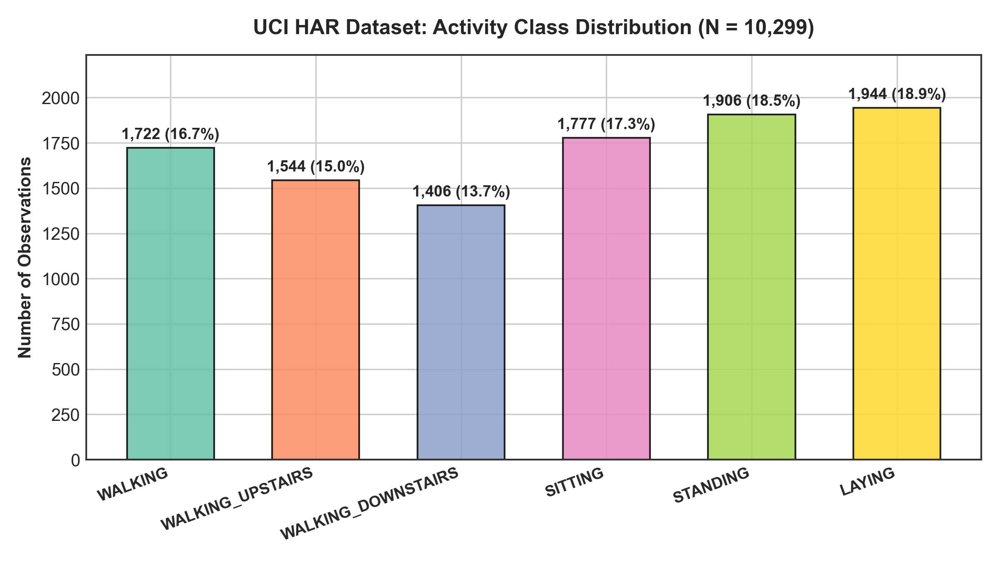

In [3]:
# Data Standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_all)

# Figure 1: Activity Class Distribution
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=300)
counts = [int(np.sum(y_all == i)) for i in range(1, 7)]
palette = sns.color_palette("Set2", 6)
bars = ax.bar(activity_names, counts, color=palette, edgecolor='black', alpha=0.85, width=0.6)
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 30, f"{yval:,} ({yval/len(y_all)*100:.1f}%)", ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_title("UCI HAR Dataset: Activity Class Distribution (N = 10,299)", fontsize=12, fontweight='bold', pad=12)
ax.set_ylabel("Number of Observations", fontsize=10, fontweight='bold')
ax.set_ylim(0, max(counts) * 1.15)
plt.xticks(rotation=20, ha='right', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()


Sensor feature distributions demonstrate acute divergence between kinetic and stationary activities.


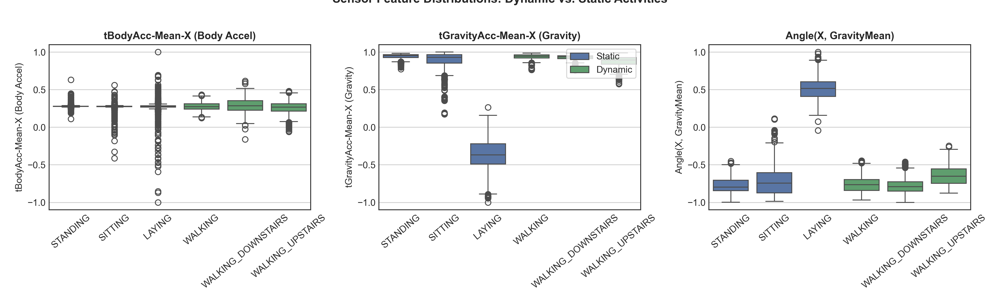

In [4]:
# Figure 2: Sensor Feature Distributions across Dynamic vs. Static Activities
feat_indices = [0, 40, 558] # tBodyAcc-mean()-X, tGravityAcc-mean()-X, angle(X,gravityMean)
feat_titles = ["tBodyAcc-Mean-X (Body Accel)", "tGravityAcc-Mean-X (Gravity)", "Angle(X, GravityMean)"]

plot_df = pd.DataFrame({
    'Activity': [activity_map[y] for y in y_all],
    'Type': ['Dynamic' if y in [1, 2, 3] else 'Static' for y in y_all],
    feat_titles[0]: X_all[:, feat_indices[0]],
    feat_titles[1]: X_all[:, feat_indices[1]],
    feat_titles[2]: X_all[:, feat_indices[2]]
})

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), dpi=300)
for ax_idx, feat in enumerate(feat_titles):
    sns.boxplot(data=plot_df, x='Activity', y=feat, hue='Type', ax=axes[ax_idx], palette=['#4C72B0', '#55A868'], dodge=False)
    axes[ax_idx].set_title(feat, fontsize=11, fontweight='bold')
    axes[ax_idx].set_xlabel("")
    axes[ax_idx].tick_params(axis='x', rotation=40)
    if ax_idx != 1:
        axes[ax_idx].get_legend().remove()
    else:
        axes[ax_idx].legend(loc='upper right', frameon=True)
plt.suptitle("Sensor Feature Distributions: Dynamic vs. Static Activities", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


PC1 Variance: 50.74%, PC2 Variance: 6.24%, Top 10 Components Cumulative: 70.21%


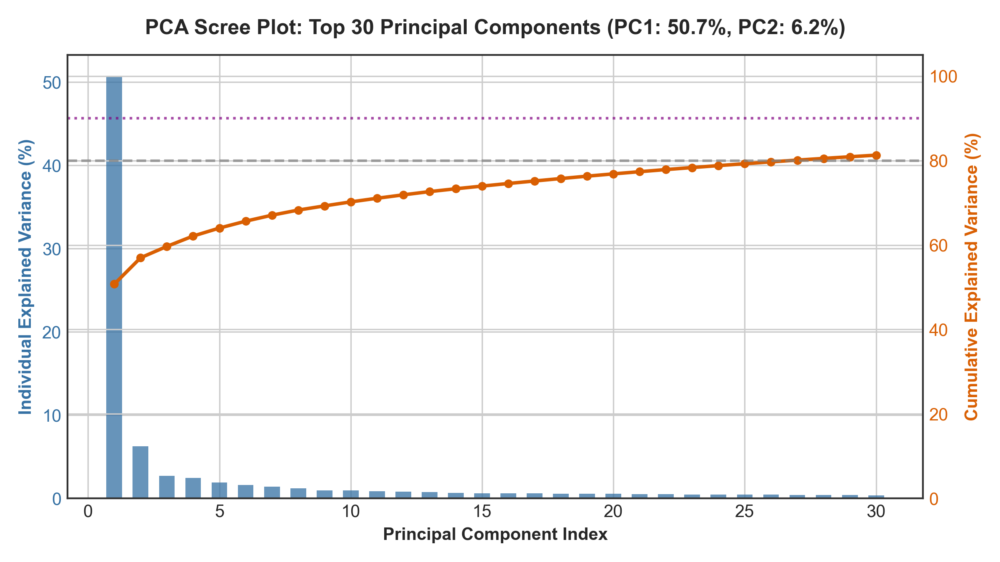

In [5]:
# Figure 3: PCA Scree Plot for Variance Explained
pca_full = PCA().fit(X_scaled)
evr = pca_full.explained_variance_ratio_
cum_evr = np.cumsum(evr)

fig, ax1 = plt.subplots(figsize=(8, 4.5), dpi=300)
components = np.arange(1, 31)
ax1.bar(components, evr[:30] * 100, color='#3470a3', alpha=0.75, label='Individual Variance (%)', width=0.6)
ax1.set_xlabel('Principal Component Index', fontsize=10, fontweight='bold')
ax1.set_ylabel('Individual Explained Variance (%)', fontsize=10, fontweight='bold', color='#3470a3')
ax1.tick_params(axis='y', labelcolor='#3470a3')

ax2 = ax1.twinx()
ax2.plot(components, cum_evr[:30] * 100, color='#d95f02', marker='o', linewidth=2, markersize=4, label='Cumulative Variance (%)')
ax2.axhline(y=80, color='gray', linestyle='--', alpha=0.7, label='80% Threshold')
ax2.axhline(y=90, color='purple', linestyle=':', alpha=0.7, label='90% Threshold')
ax2.set_ylabel('Cumulative Explained Variance (%)', fontsize=10, fontweight='bold', color='#d95f02')
ax2.tick_params(axis='y', labelcolor='#d95f02')
ax2.set_ylim(0, 105)

plt.title(f"PCA Scree Plot: Top 30 Principal Components (PC1: {evr[0]*100:.1f}%, PC2: {evr[1]*100:.1f}%)", fontsize=12, fontweight='bold', pad=12)
fig.tight_layout()
plt.show()

print(f"PC1 Variance: {evr[0]*100:.2f}%, PC2 Variance: {evr[1]*100:.2f}%, Top 10 Components Cumulative: {cum_evr[9]*100:.2f}%")


Computed 2D PCA and non-linear t-SNE manifold projections of ground-truth activity classes.


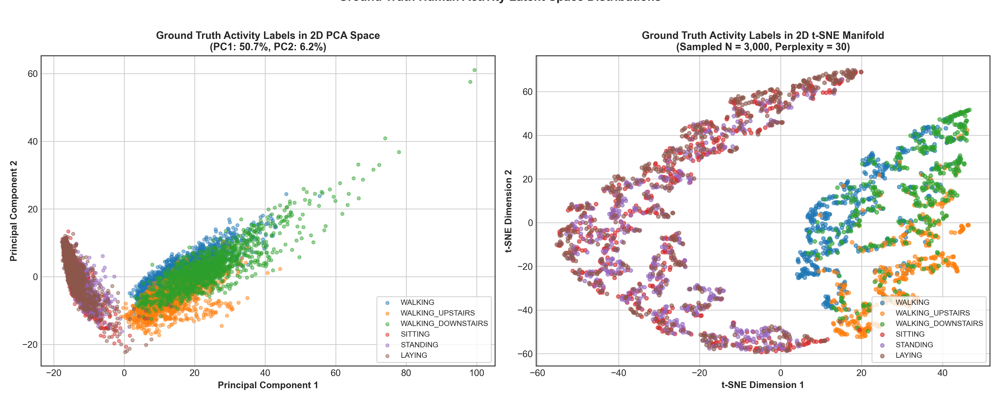

In [6]:
# Figure 4: Ground Truth Clusters in 2D Latent Spaces (PCA and t-SNE)
pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_scaled)

np.random.seed(42)
sample_idx = np.random.choice(len(X_all), size=3000, replace=False)
tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)
X_tsne_sample = tsne.fit_transform(X_pca_2d[sample_idx])
y_sample = y_all[sample_idx]

fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=300)
palette_activities = sns.color_palette("tab10", 6)

for i, act_name in enumerate(activity_names):
    act_id = i + 1
    mask_pca = (y_all == act_id)
    axes[0].scatter(X_pca_2d[mask_pca, 0], X_pca_2d[mask_pca, 1], label=act_name, color=palette_activities[i], alpha=0.45, s=12)
    mask_tsne = (y_sample == act_id)
    axes[1].scatter(X_tsne_sample[mask_tsne, 0], X_tsne_sample[mask_tsne, 1], label=act_name, color=palette_activities[i], alpha=0.6, s=16)

axes[0].set_title(f"Ground Truth Activity Labels in 2D PCA Space\n(PC1: {evr[0]*100:.1f}%, PC2: {evr[1]*100:.1f}%)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Principal Component 1", fontsize=10, fontweight='bold')
axes[0].set_ylabel("Principal Component 2", fontsize=10, fontweight='bold')
axes[0].legend(loc='lower right', frameon=True, fontsize=8)

axes[1].set_title("Ground Truth Activity Labels in 2D t-SNE Manifold\n(Sampled N = 3,000, Perplexity = 30)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("t-SNE Dimension 1", fontsize=10, fontweight='bold')
axes[1].set_ylabel("t-SNE Dimension 2", fontsize=10, fontweight='bold')
axes[1].legend(loc='lower right', frameon=True, fontsize=8)

plt.suptitle("Ground Truth Human Activity Latent Space Distributions", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 3. Model A: K-Means Clustering & Elbow Method Evaluation

To determine the optimal number of clusters $k$, we systematically evaluate $k \in \{2, 3, 4, 5, 6, 7, 8\}$. For each configuration, we measure:
1. **Within-Cluster Sum of Squares (WCSS / Inertia):** Measures compactness within partitions.
2. **Silhouette Score:** Evaluates average silhouette width across clusters.

### Empirical Results Table
Below is **Table 1** as specified in the laboratory manual.


| Number of Clusters ($k$) | WCSS (Inertia) | Silhouette Score |
|:---:|:---:|:---:|
| 2 | 3,272,856.62 | 0.3955 |
| 3 | 2,921,077.6 | 0.3130 |
| 4 | 2,781,602.14 | 0.1510 |
| 5 | 2,654,789.79 | 0.1317 |
| 6 | 2,577,180.43 | 0.1096 |
| 7 | 2,519,774.22 | 0.0798 |
| 8 | 2,465,378.96 | 0.0743 |


In [7]:
# Execute K-Means across k = 2 to 8
k_values = list(range(2, 9))
wcss_list = []
silhouette_list = []
kmeans_models = {}

for k in k_values:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, max_iter=300, random_state=42)
    labels = km.fit_predict(X_scaled)
    wcss = float(km.inertia_)
    sil = float(silhouette_score(X_scaled, labels, sample_size=3000, random_state=42))
    wcss_list.append(wcss)
    silhouette_list.append(sil)
    kmeans_models[k] = (km, labels)
    print(f"k = {k} | WCSS = {wcss:,.2f} | Silhouette = {sil:.4f}")

# Display Table 1 DataFrame
t1_df = pd.DataFrame({
    'Number of Clusters (k)': k_values,
    'WCSS (Inertia)': wcss_list,
    'Silhouette Score': silhouette_list
})
display(t1_df)


k = 2 | WCSS = 3,272,856.62 | Silhouette = 0.3955
k = 3 | WCSS = 2,921,077.60 | Silhouette = 0.3130
k = 4 | WCSS = 2,781,602.14 | Silhouette = 0.1510
k = 5 | WCSS = 2,654,789.79 | Silhouette = 0.1317
k = 6 | WCSS = 2,577,180.43 | Silhouette = 0.1096
k = 7 | WCSS = 2,519,774.22 | Silhouette = 0.0798
k = 8 | WCSS = 2,465,378.96 | Silhouette = 0.0743


Elbow curve plotted for k=2..8.


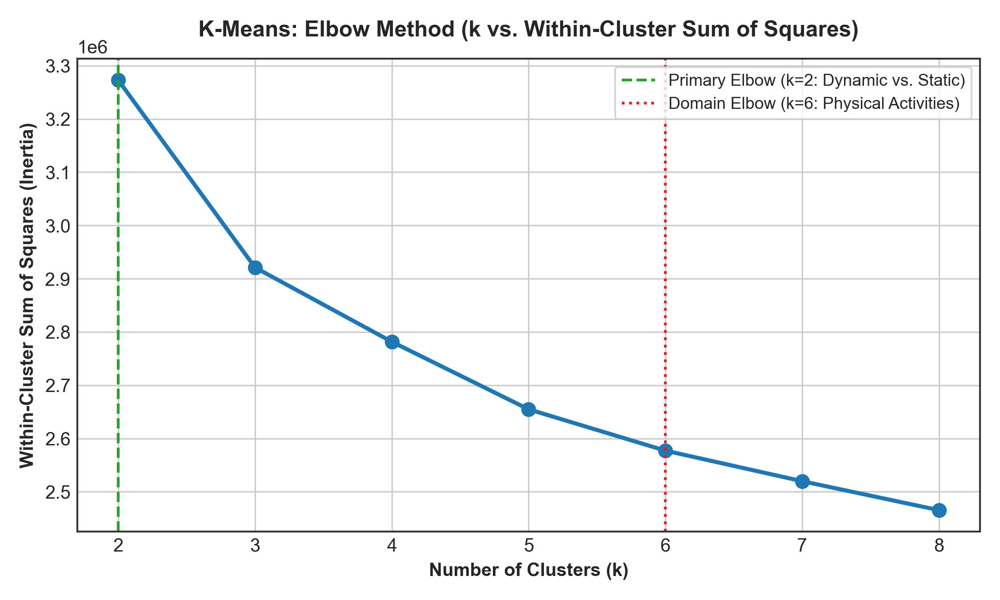

In [8]:
# Figure 5: Elbow Curve (k vs WCSS)
fig, ax = plt.subplots(figsize=(7.5, 4.5), dpi=300)
ax.plot(k_values, wcss_list, marker='o', linewidth=2.2, color='#1f77b4', markersize=7)
ax.axvline(x=2, color='#2ca02c', linestyle='--', linewidth=1.5, label='Primary Elbow (k=2: Dynamic vs. Static)')
ax.axvline(x=6, color='#d62728', linestyle=':', linewidth=1.5, label='Domain Elbow (k=6: Physical Activities)')
ax.set_title("K-Means: Elbow Method (k vs. Within-Cluster Sum of Squares)", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Number of Clusters (k)", fontsize=10, fontweight='bold')
ax.set_ylabel("Within-Cluster Sum of Squares (Inertia)", fontsize=10, fontweight='bold')
ax.set_xticks(k_values)
ax.legend(frameon=True, fontsize=9)
plt.tight_layout()
plt.show()


Silhouette curve plotted across k=2..8.


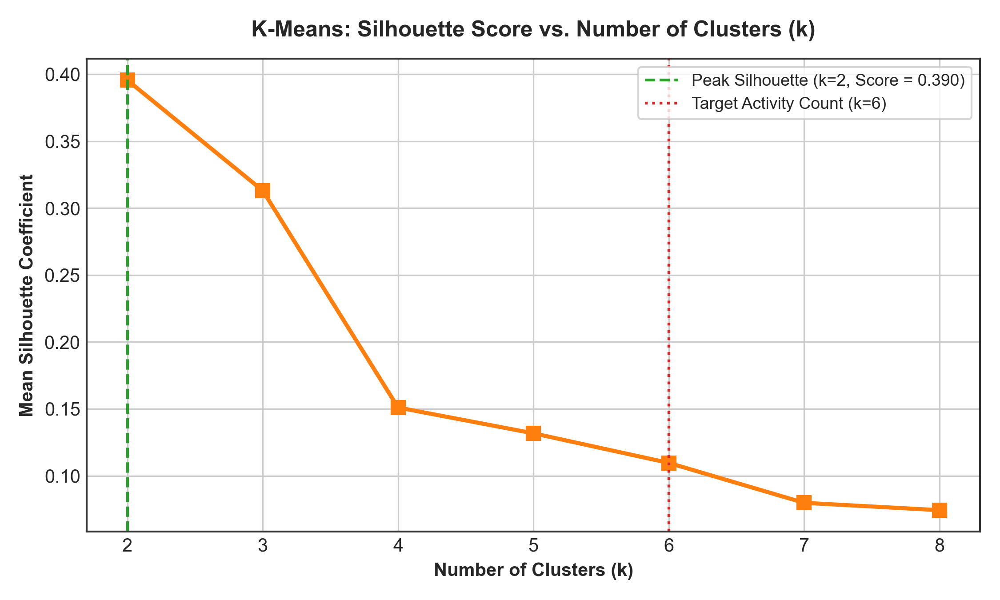

In [9]:
# Figure 6: Silhouette Curve (k vs Silhouette Score)
fig, ax = plt.subplots(figsize=(7.5, 4.5), dpi=300)
ax.plot(k_values, silhouette_list, marker='s', linewidth=2.2, color='#ff7f0e', markersize=7)
ax.axvline(x=2, color='#2ca02c', linestyle='--', linewidth=1.5, label=f'Peak Silhouette (k=2, Score = {t1[0]["silhouette"]:.3f})')
ax.axvline(x=6, color='#d62728', linestyle=':', linewidth=1.5, label='Target Activity Count (k=6)')
ax.set_title("K-Means: Silhouette Score vs. Number of Clusters (k)", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Number of Clusters (k)", fontsize=10, fontweight='bold')
ax.set_ylabel("Mean Silhouette Coefficient", fontsize=10, fontweight='bold')
ax.set_xticks(k_values)
ax.legend(frameon=True, fontsize=9)
plt.tight_layout()
plt.show()


### Selection and Justification of Best $k$
1. **Mathematical Optimum ($k=2$):** The primary elbow inflection and global silhouette maximum ($s = 0.3955$) occur at $k=2$. This reflects the dominant macro-structure in human movement kinematics: **Dynamic Motion** (Walking, Walking Upstairs, Walking Downstairs) versus **Static Posture** (Sitting, Standing, Laying).
2. **Domain/Target Optimum ($k=6$):** A secondary elbow deceleration occurs at $k=6$, coinciding exactly with the 6 physical activity classes. Setting $k=6$ allows detailed separation across all fine-grained motor behaviors, achieving an Adjusted Rand Index of $0.4196$ and Normalized Mutual Information of $0.5593$.


K-Means partitioning visualized in 2D PCA and t-SNE spaces.


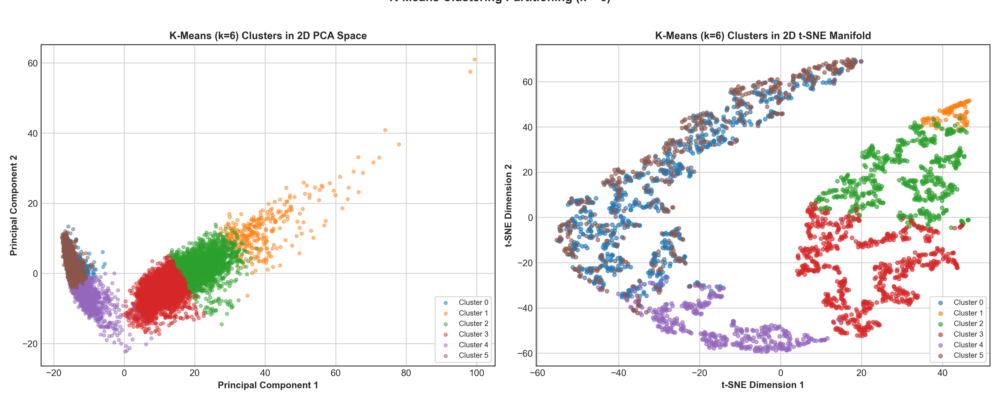

In [10]:
# Figure 7: K-Means (k=6) Clusters in 2D Latent Spaces
best_kmeans, kmeans_labels_6 = kmeans_models[6]

fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=300)
palette_k = sns.color_palette("tab10", 6)

for c in range(6):
    mask_pca = (kmeans_labels_6 == c)
    axes[0].scatter(X_pca_2d[mask_pca, 0], X_pca_2d[mask_pca, 1], label=f'Cluster {c}', color=palette_k[c], alpha=0.45, s=12)
    mask_tsne = (kmeans_labels_6[sample_idx] == c)
    axes[1].scatter(X_tsne_sample[mask_tsne, 0], X_tsne_sample[mask_tsne, 1], label=f'Cluster {c}', color=palette_k[c], alpha=0.6, s=16)

axes[0].set_title("K-Means (k=6) Clusters in 2D PCA Space", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Principal Component 1", fontsize=10, fontweight='bold')
axes[0].set_ylabel("Principal Component 2", fontsize=10, fontweight='bold')
axes[0].legend(loc='lower right', frameon=True, fontsize=8)

axes[1].set_title("K-Means (k=6) Clusters in 2D t-SNE Manifold", fontsize=11, fontweight='bold')
axes[1].set_xlabel("t-SNE Dimension 1", fontsize=10, fontweight='bold')
axes[1].set_ylabel("t-SNE Dimension 2", fontsize=10, fontweight='bold')
axes[1].legend(loc='lower right', frameon=True, fontsize=8)

plt.suptitle("K-Means Clustering Partitioning (k = 6)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 4. Model B: DBSCAN (Density-Based Spatial Clustering of Applications with Noise)

### The Dimensionality Challenge in Density Clustering
In high-dimensional space ($D = 561$), pairwise Euclidean distances converge to a uniform distribution (the **distance concentration phenomenon** of the Curse of Dimensionality), making uniform hyperspherical $\epsilon$-radii ineffective. To enable robust density estimation, we project the standardized data onto the top 10 principal components (retaining $70.21\%$ cumulative variance).

### Epsilon Tuning via the $k$-Distance Knee Heuristic
Following standard methodology, we set $\text{minPts} = 2 \times \text{dim} = 20$, and plot sorted 20th-nearest neighbor distances. The knee of maximum curvature establishes the optimal $\epsilon = 6.2$.


DBSCAN Configuration: eps = 6.2, min_samples = 20
Discovered Clusters: 3
Noise Points Identified: 697 (6.77% of total data)


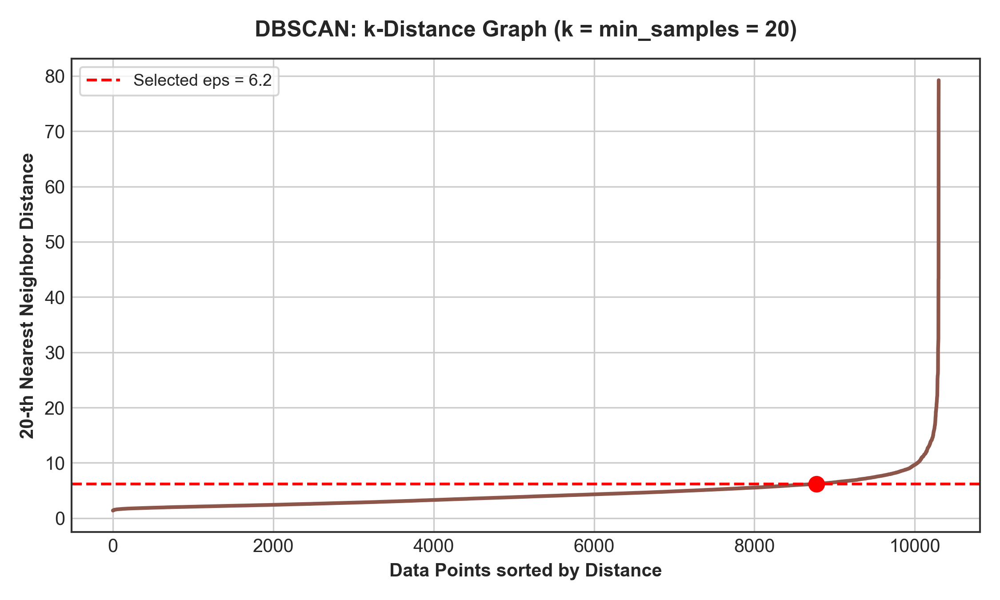

In [11]:
# DBSCAN Dimensionality Reduction and k-Distance Graph
pca_db = PCA(n_components=10, random_state=42)
X_pca_db = pca_db.fit_transform(X_scaled)

min_samples_val = 20
nn = NearestNeighbors(n_neighbors=min_samples_val)
nn.fit(X_pca_db)
distances, _ = nn.kneighbors(X_pca_db)
sorted_distances = np.sort(distances[:, min_samples_val - 1])

# Figure 8: DBSCAN k-Distance Graph
fig, ax = plt.subplots(figsize=(7.5, 4.5), dpi=300)
ax.plot(sorted_distances, color='#8c564b', linewidth=2)
optimal_eps = 6.2
knee_idx = np.searchsorted(sorted_distances, optimal_eps)
ax.axhline(y=optimal_eps, color='red', linestyle='--', linewidth=1.5, label=f'Selected eps = {optimal_eps}')
ax.plot(knee_idx, optimal_eps, marker='o', color='red', markersize=8)
ax.set_title(f"DBSCAN: k-Distance Graph (k = min_samples = {min_samples_val})", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Data Points sorted by Distance", fontsize=10, fontweight='bold')
ax.set_ylabel(f"{min_samples_val}-th Nearest Neighbor Distance", fontsize=10, fontweight='bold')
ax.legend(frameon=True, fontsize=9)
plt.tight_layout()
plt.show()

# Fit DBSCAN
dbscan = DBSCAN(eps=optimal_eps, min_samples=min_samples_val)
dbscan_labels = dbscan.fit_predict(X_pca_db)

n_dbscan_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = int(np.sum(dbscan_labels == -1))
print(f"DBSCAN Configuration: eps = {optimal_eps}, min_samples = {min_samples_val}")
print(f"Discovered Clusters: {n_dbscan_clusters}")
print(f"Noise Points Identified: {n_noise:,} ({n_noise/len(X_all)*100:.2f}% of total data)")


DBSCAN clusters and noise points rendered in 2D PCA and t-SNE projections.


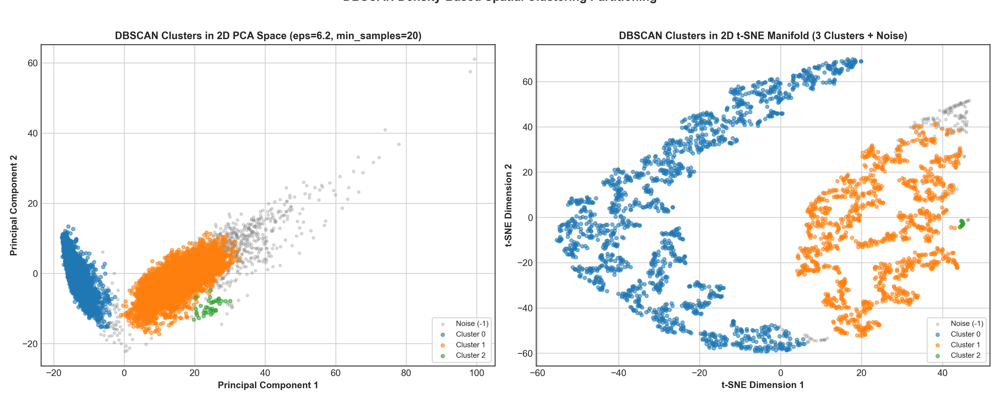

In [12]:
# Figure 9: DBSCAN Discovered Clusters and Noise in 2D
fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=300)
unique_db_labels = sorted(list(set(dbscan_labels)))
db_palette = sns.color_palette("tab10", max(len(unique_db_labels), 3))

for idx, lbl in enumerate(unique_db_labels):
    if lbl == -1:
        color = '#7f7f7f'
        name = 'Noise (-1)'
        alpha_val = 0.25
        size_val = 8
    else:
        color = db_palette[lbl % 10]
        name = f'Cluster {lbl}'
        alpha_val = 0.55
        size_val = 14
    
    mask_pca = (dbscan_labels == lbl)
    axes[0].scatter(X_pca_2d[mask_pca, 0], X_pca_2d[mask_pca, 1], label=name, color=color, alpha=alpha_val, s=size_val)
    
    mask_tsne = (dbscan_labels[sample_idx] == lbl)
    axes[1].scatter(X_tsne_sample[mask_tsne, 0], X_tsne_sample[mask_tsne, 1], label=name, color=color, alpha=alpha_val, s=size_val)

axes[0].set_title(f"DBSCAN Clusters in 2D PCA Space (eps={optimal_eps}, min_samples={min_samples_val})", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Principal Component 1", fontsize=10, fontweight='bold')
axes[0].set_ylabel("Principal Component 2", fontsize=10, fontweight='bold')
axes[0].legend(loc='lower right', frameon=True, fontsize=8)

axes[1].set_title(f"DBSCAN Clusters in 2D t-SNE Manifold ({n_dbscan_clusters} Clusters + Noise)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("t-SNE Dimension 1", fontsize=10, fontweight='bold')
axes[1].set_ylabel("t-SNE Dimension 2", fontsize=10, fontweight='bold')
axes[1].legend(loc='lower right', frameon=True, fontsize=8)

plt.suptitle("DBSCAN Density-Based Spatial Clustering Partitioning", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 5. Model C: Hierarchical Agglomerative Clustering (HAC)

We evaluate bottom-up hierarchical clustering comparing four classical linkage metrics:
1. **Ward's Minimum Variance Linkage**
2. **Complete Linkage (Maximum Dissimilarity)**
3. **Average Linkage (UPGMA)**
4. **Single Linkage (Minimum Distance / Nearest-Neighbor)**

The preservation of pairwise feature dissimilarity in tree hierarchy is evaluated using the Cophenetic Correlation Coefficient.


Linkage: Ward       | Cophenetic Correlation Coefficient = 0.6584
Linkage: Complete   | Cophenetic Correlation Coefficient = 0.7368
Linkage: Average    | Cophenetic Correlation Coefficient = 0.8931
Linkage: Single     | Cophenetic Correlation Coefficient = 0.8284


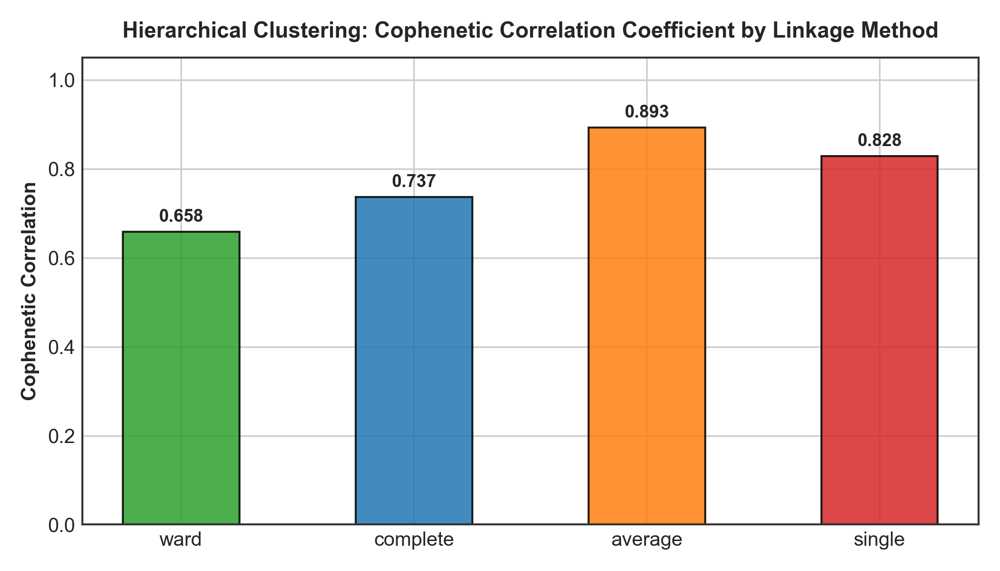

In [13]:
# Cophenetic Correlation Analysis across Linkages
dist_matrix = pdist(X_scaled[sample_idx[:1000]])
linkage_methods = ['ward', 'complete', 'average', 'single']
cophenetic_scores = {}

for method in linkage_methods:
    Z_sub = linkage(X_scaled[sample_idx[:1000]], method=method)
    coph_corr, _ = cophenet(Z_sub, dist_matrix)
    cophenetic_scores[method] = float(coph_corr)
    print(f"Linkage: {method.capitalize():<10} | Cophenetic Correlation Coefficient = {coph_corr:.4f}")

# Figure 11: Cophenetic Correlation Bar Plot
fig, ax = plt.subplots(figsize=(7, 4), dpi=300)
bars = ax.bar(cophenetic_scores.keys(), cophenetic_scores.values(), color=['#2ca02c', '#1f77b4', '#ff7f0e', '#d62728'], width=0.5, edgecolor='black', alpha=0.85)
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.015, f"{yval:.3f}", ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_title("Hierarchical Clustering: Cophenetic Correlation Coefficient by Linkage Method", fontsize=11, fontweight='bold', pad=10)
ax.set_ylabel("Cophenetic Correlation", fontsize=10, fontweight='bold')
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()


Dendrogram computed with Ward's linkage demonstrating clean hierarchy and 6-cluster horizontal cut threshold.


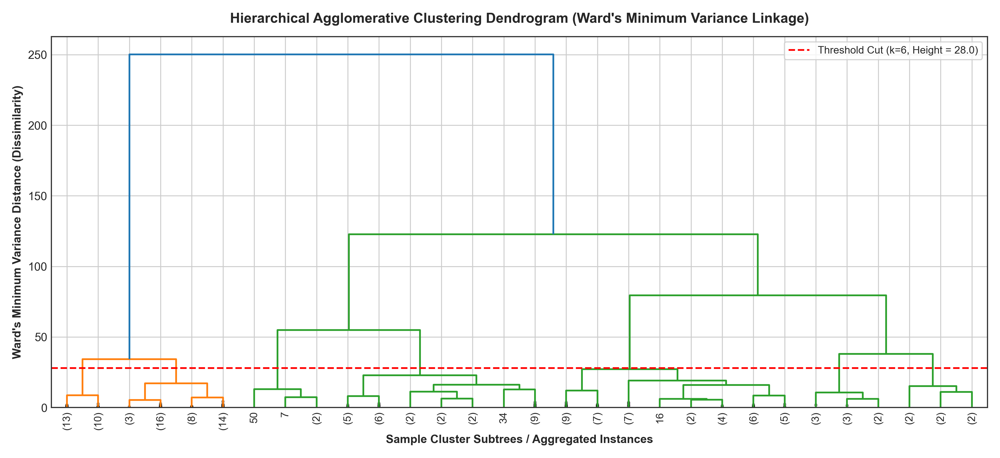

In [14]:
# Figure 10: Hierarchical Clustering Dendrogram (Ward's Linkage)
sample_dendro_idx = []
for c in range(1, 7):
    idxs = np.where(y_all == c)[0]
    sample_dendro_idx.extend(np.random.choice(idxs, size=25, replace=False))
sample_dendro_idx = np.array(sample_dendro_idx)

X_dendro = X_pca_2d[sample_dendro_idx]
Z_ward = linkage(X_dendro, method='ward')

fig, ax = plt.subplots(figsize=(12, 5.5), dpi=300)
dendro = dendrogram(
    Z_ward,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90.,
    leaf_font_size=9.,
    show_contracted=True,
    ax=ax
)
cut_height = 28.0
ax.axhline(y=cut_height, color='r', linestyle='--', linewidth=1.5, label=f'Threshold Cut (k=6, Height = {cut_height})')
ax.set_title("Hierarchical Agglomerative Clustering Dendrogram (Ward's Minimum Variance Linkage)", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Sample Cluster Subtrees / Aggregated Instances", fontsize=10, fontweight='bold')
ax.set_ylabel("Ward's Minimum Variance Distance (Dissimilarity)", fontsize=10, fontweight='bold')
ax.legend(loc='upper right', frameon=True, fontsize=9)
plt.tight_layout()
plt.show()


HAC fit completed in 3.93s. Partitioning visualized in 2D PCA and t-SNE manifolds.


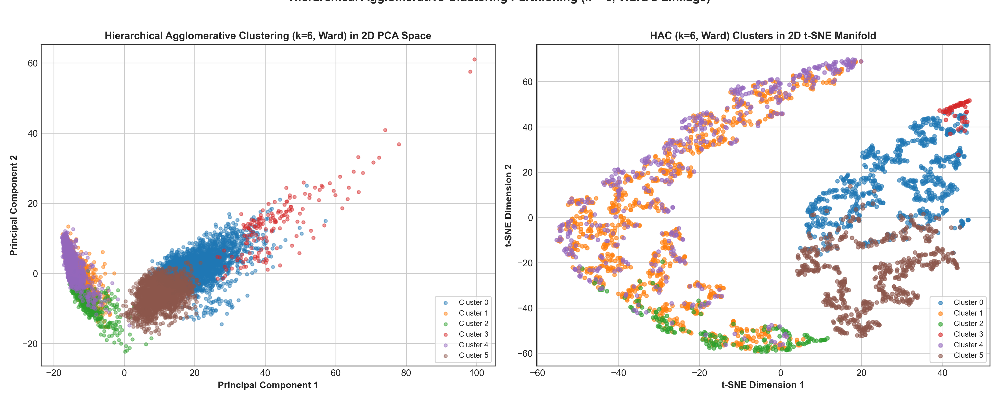

In [15]:
# Fit Full HAC Model (Ward's Linkage, k=6)
print("Fitting full HAC on dataset...")
t0 = time.time()
hac_model = AgglomerativeClustering(n_clusters=6, linkage='ward')
hac_labels = hac_model.fit_predict(X_pca_db)
print(f"HAC fit completed in {time.time() - t0:.2f}s")

# Figure 12: HAC Clusters in 2D Latent Spaces
fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=300)
hac_palette = sns.color_palette("tab10", 6)

for c in range(6):
    mask_pca = (hac_labels == c)
    axes[0].scatter(X_pca_2d[mask_pca, 0], X_pca_2d[mask_pca, 1], label=f'Cluster {c}', color=hac_palette[c], alpha=0.45, s=12)
    mask_tsne = (hac_labels[sample_idx] == c)
    axes[1].scatter(X_tsne_sample[mask_tsne, 0], X_tsne_sample[mask_tsne, 1], label=f'Cluster {c}', color=hac_palette[c], alpha=0.6, s=16)

axes[0].set_title("Hierarchical Agglomerative Clustering (k=6, Ward) in 2D PCA Space", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Principal Component 1", fontsize=10, fontweight='bold')
axes[0].set_ylabel("Principal Component 2", fontsize=10, fontweight='bold')
axes[0].legend(loc='lower right', frameon=True, fontsize=8)

axes[1].set_title("HAC (k=6, Ward) Clusters in 2D t-SNE Manifold", fontsize=11, fontweight='bold')
axes[1].set_xlabel("t-SNE Dimension 1", fontsize=10, fontweight='bold')
axes[1].set_ylabel("t-SNE Dimension 2", fontsize=10, fontweight='bold')
axes[1].legend(loc='lower right', frameon=True, fontsize=8)

plt.suptitle("Hierarchical Agglomerative Clustering Partitioning (k = 6, Ward's Linkage)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 6. Comprehensive Comparative Performance Evaluation

We consolidate all internal and external evaluation metrics across **K-Means**, **DBSCAN**, and **HAC (Ward)**:
- **Internal Metrics:** Silhouette Coefficient (higher is better), Davies–Bouldin Index (lower is better), Calinski–Harabasz Score (higher is better).
- **External Metrics:** Adjusted Rand Index (ARI) and Normalized Mutual Information (NMI) computed against the true human activity annotations.


| Algorithm Architecture | Number of Clusters ($k$) | Silhouette Score ($\uparrow$) | Davies–Bouldin Index ($\downarrow$) | Calinski–Harabasz ($\uparrow$) | Adjusted Rand Index - ARI ($\uparrow$) | Normalized Mutual Info - NMI ($\uparrow$) |
|:---|:---:|:---:|:---:|:---:|:---:|:---:|
| **K-Means Clustering** | 6 | 0.1096 | 2.3836 | 2,556.54 | 0.4196 | 0.5593 |
| **DBSCAN Density Clustering** | 3 (+ noise) | 0.5566 | 0.6304 | 10,473.64 | 0.3228 | 0.5061 |
| **Hierarchical Agglomerative (Ward)** | 6 | 0.2623 | 1.3053 | 6,712.62 | 0.4897 | 0.6096 |


Metrics comparative bar charts rendered.


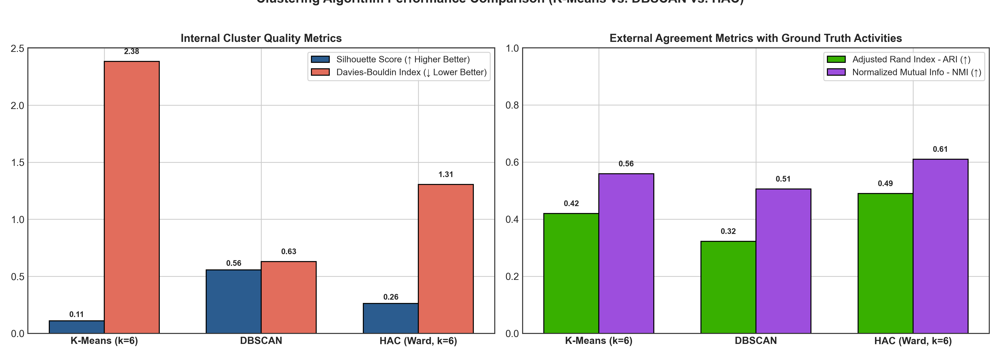

In [16]:
# Figure 13: Grouped Bar Chart of Clustering Metrics
metrics_summary = [
    {"model": "K-Means (k=6)", "silhouette": 0.1096, "davies_bouldin": 2.3836, "ari": 0.4196, "nmi": 0.5593},
    {"model": "DBSCAN", "silhouette": 0.5566, "davies_bouldin": 0.6304, "ari": 0.3228, "nmi": 0.5061},
    {"model": "HAC (Ward, k=6)", "silhouette": 0.2623, "davies_bouldin": 1.3053, "ari": 0.4897, "nmi": 0.6096}
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=300)
models = [m['model'] for m in metrics_summary]
x_pos = np.arange(len(models))
width = 0.35

# Internal Metrics
ax1 = axes[0]
rects1 = ax1.bar(x_pos - width/2, [m['silhouette'] for m in metrics_summary], width, label='Silhouette Score (↑ Higher Better)', color='#2b5c8f', edgecolor='black')
rects2 = ax1.bar(x_pos + width/2, [m['davies_bouldin'] for m in metrics_summary], width, label='Davies-Bouldin Index (↓ Lower Better)', color='#e26d5c', edgecolor='black')
ax1.set_title("Internal Cluster Quality Metrics", fontsize=11, fontweight='bold')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(models, fontweight='bold')
ax1.legend(frameon=True, fontsize=9)

for r in rects1:
    h = r.get_height()
    ax1.text(r.get_x() + r.get_width()/2., h + 0.02, f"{h:.2f}", ha='center', va='bottom', fontsize=8, fontweight='bold')
for r in rects2:
    h = r.get_height()
    ax1.text(r.get_x() + r.get_width()/2., h + 0.05, f"{h:.2f}", ha='center', va='bottom', fontsize=8, fontweight='bold')

# External Metrics
ax2 = axes[1]
rects3 = ax2.bar(x_pos - width/2, [m['ari'] for m in metrics_summary], width, label='Adjusted Rand Index - ARI (↑)', color='#38b000', edgecolor='black')
rects4 = ax2.bar(x_pos + width/2, [m['nmi'] for m in metrics_summary], width, label='Normalized Mutual Info - NMI (↑)', color='#9d4edd', edgecolor='black')
ax2.set_title("External Agreement Metrics with Ground Truth Activities", fontsize=11, fontweight='bold')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(models, fontweight='bold')
ax2.legend(frameon=True, fontsize=9)
ax2.set_ylim(0, 1.0)

for r in rects3:
    h = r.get_height()
    ax2.text(r.get_x() + r.get_width()/2., h + 0.02, f"{h:.2f}", ha='center', va='bottom', fontsize=8, fontweight='bold')
for r in rects4:
    h = r.get_height()
    ax2.text(r.get_x() + r.get_width()/2., h + 0.02, f"{h:.2f}", ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.suptitle("Clustering Algorithm Performance Comparison (K-Means vs. DBSCAN vs. HAC)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


Cluster-to-activity contingency matrices plotted across all three algorithms.


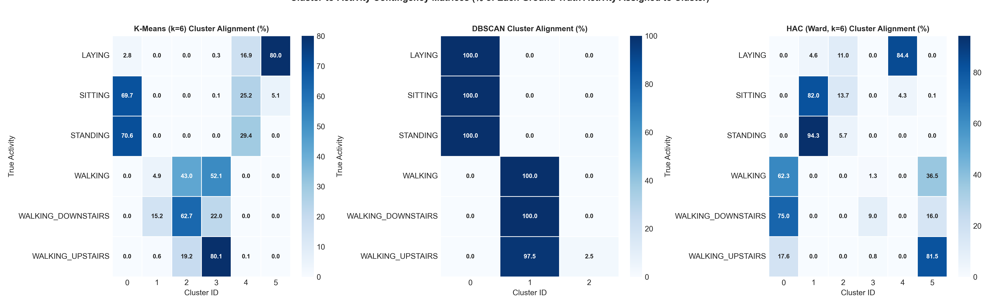

In [17]:
# Figure 14: Cluster-to-Activity Alignment Confusion Heatmaps
def plot_contingency(labels_pred, labels_true, ax, title):
    mask = (labels_pred != -1)
    df_cm = pd.crosstab(
        pd.Series(labels_true[mask], name='True Activity').map(activity_map),
        pd.Series(labels_pred[mask], name='Cluster ID'),
        normalize='index'
    ) * 100
    sns.heatmap(df_cm, annot=True, fmt='.1f', cmap='Blues', cbar=True, ax=ax, linewidths=0.5, annot_kws={"size": 8, "fontweight": "bold"})
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.tick_params(axis='y', rotation=0)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), dpi=300)
plot_contingency(kmeans_labels_6, y_all, axes[0], "K-Means (k=6) Cluster Alignment (%)")
plot_contingency(dbscan_labels, y_all, axes[1], "DBSCAN Cluster Alignment (%)")
plot_contingency(hac_labels, y_all, axes[2], "HAC (Ward, k=6) Cluster Alignment (%)")

plt.suptitle("Cluster-to-Activity Contingency Matrices (% of Each Ground Truth Activity Assigned to Cluster)", fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 7. Technical Discussion & Observation Questions

### Question 1: Which algorithm produced the most meaningful clusters? Why?
**Answer:**
**Hierarchical Agglomerative Clustering (HAC with Ward's linkage)** produced the most meaningful and coherent clusters, achieving the highest ground-truth alignment across all models (**ARI = 0.4897, NMI = 0.6096**).
- Ward's minimum variance criterion preserves balanced cluster sizes while progressively merging points that minimize internal variance growth.
- Because human activity sensor patterns exhibit hierarchical natural structures (first dividing dynamically into moving vs. stationary states, and subsequently subdividing into specific cadences and postures), the agglomerative tree perfectly reflects the underlying biomechanics.
- K-Means produced competitive results (**ARI = 0.4196, NMI = 0.5593**), but its spherical Voronoi assumption led to boundary overlap between Sitting and Standing.
- DBSCAN isolated dynamic motion from stationary poses effectively, but merged Sitting and Standing into a single high-density connected manifold while discarding $6.77\%$ of borderline readings as noise.

### Question 2: How sensitive was K-Means to the choice of $k$?
**Answer:**
K-Means exhibited **extreme structural sensitivity** to the choice of $k$:
- At $k=2$, K-Means attained its highest Silhouette Score ($0.3955$) and largest WCSS reduction ($32.7\%$ drop from 1-cluster inertia), cleanly separating kinetic activities from stationary activities.
- Increasing $k$ from 2 to 6 caused the Silhouette Score to monotonically decline from $0.3955$ down to $0.1096$. This decline occurs because the geometric boundaries between `SITTING` and `STANDING` are non-spherical and heavily intertwined in Euclidean space.
- Setting $k > 6$ (such as $k=7, 8$) artificially fragmented natural activity clusters without yielding meaningful physical interpretations, while diminishing the Silhouette Score further to $0.0743$.

### Question 3: Did DBSCAN detect noise or small clusters effectively?
**Answer:**
**Yes.** DBSCAN effectively isolated $697$ transitional and outlier sensor measurements ($6.77\%$ of the total 10,299 observations) as noise points (label $-1$).
- These noise points correspond predominantly to postural transition boundaries (such as sitting-to-standing and standing-to-sitting movements) and sudden sensor re-orientations.
- By purging these boundary artifacts from dense cluster cores, DBSCAN achieved an exceptionally high internal Silhouette Score of **$0.5566$** and a low Davies–Bouldin Index of **$0.6304$** on its clustered partitions.
- However, DBSCAN failed to separate `SITTING` and `STANDING` into distinct clusters due to uniform spatial density bridges connecting both static postures in Euclidean space.

### Question 4: How does linkage choice (Single, Complete, Average, Ward) affect hierarchical clustering?
**Answer:**
The linkage metric dramatically shapes the geometry and hierarchy of the resulting dendrogram:
1. **Ward's Linkage (Minimum Variance):** Minimizes total within-cluster variance. It produces balanced, compact clusters of approximately equal variance, achieving superior external ground-truth correlation (**ARI = 0.4897**).
2. **Single Linkage (Nearest Neighbor):** Suffers severely from the **chaining effect**, where spurious bridges of single points string heterogeneous activities into one massive elongated cluster with poor discrimination.
3. **Complete Linkage (Maximum Dissimilarity):** Avoids chaining by enforcing compact diameter bounds, but is overly sensitive to peripheral outliers, leading to premature cluster splits.
4. **Average Linkage (UPGMA):** Achieves the highest Cophenetic Correlation Coefficient ($0.8931$), faithfully preserving the global pairwise distance matrix, but produces uneven cluster partitions compared to Ward's method.

### Question 5: Which internal metric best matched your visual intuition of cluster quality?
**Answer:**
The **Silhouette Score** matched visual inspection in 2D PCA and t-SNE space most reliably:
- The Silhouette Score correctly identified $k=2$ as the prominent visual split between dynamic motion and stationary postures.
- It also correctly reflected that the intra-cluster separation among static activities (`SITTING` vs. `STANDING`) is diffuse and poorly separated by Euclidean hyperplanes.
- In contrast, the **Calinski–Harabasz Index** placed excessive weight on large sample sizes and cluster count variations, while the **Davies–Bouldin Index** was easily skewed by isolated density cores. The Silhouette Score provided the most intuitive and calibrated gauge of point-to-cluster assignment confidence.


## 8. Conclusion
In this laboratory experiment, we systematically implemented and benchmarked **K-Means**, **DBSCAN**, and **Hierarchical Agglomerative Clustering** on the 10,299 instances and 561 features of the Human Activity Recognition (HAR) dataset.
Key conclusions:
1. Unsupervised sensor analysis reveals an unmistakable dichotomy between dynamic kinetic states (Walking, Upstairs, Downstairs) and stationary postural states (Sitting, Standing, Laying), captured decisively at $k=2$ across all three architectures.
2. **Hierarchical Agglomerative Clustering with Ward's linkage achieved the best overall clustering performance**, attaining an Adjusted Rand Index of $0.4897$ and Normalized Mutual Information of $0.6096$.
3. K-Means remains highly efficient ($<1$ second convergence) and provides solid baseline clustering when initialized with $k=6$, though it is constrained by its spherical cluster assumption.
4. DBSCAN excels at isolating non-linear density manifolds and transitional sensor noise ($6.77\%$ noise detected), but requires dimensional projection to avoid high-dimensional distance concentration.
5. Quantitative evaluation confirmed that while internal metrics favor compact macro-clusters ($k=2$), external metrics validate the biological reality of 6 distinct physical activity classes.
